# Análisis del baseline SINCA — notebook base

Notebook de arranque para **análisis puntuales** sobre los resultados del baseline (Fase 3). Corre dentro del Space `sinca-dev` de SageMaker Studio (dominio `sinca-studio`), que ejecuta como rol `sinca-dev-role`: **no hace falta (ni se debe) escribir credenciales AWS**.

> **Encender**: SageMaker Console → Studio → dominio `sinca-studio` → Spaces → `sinca-dev` → **Open Studio** (JupyterLab).
> **Trabajar**: todo este notebook.
> **Apagar**: SageMaker Console → Studio → Spaces → `sinca-dev` → **Stop**. Solo con la app detenida dejás de pagar cómputo (ver sección final).

## Fuentes de datos disponibles

- `s3://sinca-data/validated/` — series validadas (SINCA, Open-Meteo, feriados).
- `s3://sinca-mlflow/_mlflow/mlflow.sqlite` — métricas/parámetros por run.
- `s3://sinca-mlflow/_mlflow/mlruns/.../artifacts/predictions.parquet` — predicciones por serie (tras el re-run del baseline).

In [1]:
import io
import os
import sqlite3
import tempfile

import boto3
import pandas as pd
import matplotlib.pyplot as plt

BUCKET_DATA = "sinca-data"
BUCKET_MLFLOW = "sinca-mlflow"
MLFLOW_PREFIX = "_mlflow"

# boto3 usa automáticamente el rol del Space (sinca-dev-role). No usar profile ni claves.
s3 = boto3.client("s3")

In [2]:
# Descarga el backend SQLite de MLflow y lista los runs.
tmp = tempfile.mkdtemp()
db = os.path.join(tmp, "mlflow.sqlite")
s3.download_file(BUCKET_MLFLOW, f"{MLFLOW_PREFIX}/mlflow.sqlite", db)

con = sqlite3.connect(db)
runs = pd.read_sql_query("SELECT run_uuid, name, status, start_time FROM runs ORDER BY start_time DESC", con)
metrics = pd.read_sql_query("SELECT run_uuid, key, value FROM metrics", con)
con.close()

display(runs.head(20))
display(metrics.head(20))

,run_uuid,name,status,start_time
0,49e477a3d9884f0bb5dac35c4534caff,sinca-persistence-baseline,FINISHED,1793032559907
1,bb801d0e4dc34c00b47c7adbacd455b2,sinca-padre_las_casas_ii-lightgbm-v1,FINISHED,1793032558903
2,30f29171ba3549edb4ef743352704db7,sinca-padre_las_casas_ii-lightgbm-v1,FINISHED,1793032149074
3,17c46edf7f734453b8c580afc4e4a6ec,sinca-nielol-lightgbm-v1,FINISHED,1793031836140
4,cb9649e161294a079e0467d5a61a7b16,sinca-nielol-lightgbm-v1,FINISHED,1793031323873
5,f0db6babaec64d41952287cedbc355e1,sinca-las_encinas-lightgbm-v1,FINISHED,1793031019577
6,a1a6af374d2a4210ac528541ee560c89,sinca-las_encinas-lightgbm-v1,FINISHED,1793030601177


,run_uuid,key,value
0,a1a6af374d2a4210ac528541ee560c89,train_loss,7.896605
1,a1a6af374d2a4210ac528541ee560c89,test_loss,19.664628
2,a1a6af374d2a4210ac528541ee560c89,rolling_weighted_rmse_mean,19.865557
3,a1a6af374d2a4210ac528541ee560c89,rolling_weighted_rmse_std,20.060631
4,a1a6af374d2a4210ac528541ee560c89,test_weighted_rmse,19.664628
5,a1a6af374d2a4210ac528541ee560c89,test_rmse,19.664628
6,a1a6af374d2a4210ac528541ee560c89,test_mse,386.697589
7,a1a6af374d2a4210ac528541ee560c89,test_n,2016.000000
8,a1a6af374d2a4210ac528541ee560c89,test_mse_las_encinas_pm10,386.697589
9,a1a6af374d2a4210ac528541ee560c89,test_rmse_las_encinas_pm10,19.664628


In [3]:
# Lista e inspecciona los Parquet validados de SINCA (ejemplo).
resp = s3.list_objects_v2(Bucket=BUCKET_DATA, Prefix="validated/sinca/", MaxKeys=20)
keys = [o["Key"] for o in resp.get("Contents", []) if o["Key"].endswith(".parquet")]
print(keys[:10])

if keys:
    body = s3.get_object(Bucket=BUCKET_DATA, Key=keys[0])["Body"].read()
    df = pd.read_parquet(io.BytesIO(body))
    display(df.head())

['validated/sinca/estacion=las_encinas/year=2021/month=01/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=02/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=03/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=04/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=05/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=06/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=07/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=08/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=09/data.parquet', 'validated/sinca/estacion=las_encinas/year=2021/month=10/data.parquet']


,estacion,timestamp,co,pm10,pm25,pres,rain,rhum,temp,wspd,day_of_week,gec_window,is_holiday,icap_pm10,icap_pm25
0,Las Encinas,2021-01-01 01:00:00-03:00,0.75,28.0,6.0,1006.01,1.345250e-43,NaN,10.95840,0.716904,4,0,1,NaN,NaN
1,Las Encinas,2021-01-01 02:00:00-03:00,0.72,24.0,6.0,1005.25,1.121040e-43,NaN,10.46260,0.674439,4,0,1,NaN,NaN
2,Las Encinas,2021-01-01 03:00:00-03:00,0.63,20.0,6.0,1005.00,8.968310e-44,NaN,10.04260,0.638826,4,0,1,NaN,NaN
3,Las Encinas,2021-01-01 04:00:00-03:00,0.61,17.0,7.0,1005.42,6.726230e-44,NaN,9.85254,0.528182,4,0,1,NaN,NaN
4,Las Encinas,2021-01-01 05:00:00-03:00,0.60,14.0,5.0,1006.42,4.484160e-44,NaN,9.72086,0.896683,4,0,1,NaN,NaN


In [4]:
# Localiza y lee las predicciones persistidas de los runs (columna predictions.parquet).
listing = s3.list_objects_v2(Bucket=BUCKET_MLFLOW, Prefix=f"{MLFLOW_PREFIX}/mlruns/")
all_keys = [o["Key"] for o in listing.get("Contents", [])]
pred_keys = [k for k in all_keys if k.endswith("artifacts/predictions.parquet")]
print(pred_keys)

pred = None
if pred_keys:
    body = s3.get_object(Bucket=BUCKET_MLFLOW, Key=pred_keys[0])["Body"].read()
    pred = pd.read_parquet(io.BytesIO(body))
    display(pred.head())

['_mlflow/mlruns/17c46edf7f734453b8c580afc4e4a6ec/artifacts/predictions.parquet', '_mlflow/mlruns/30f29171ba3549edb4ef743352704db7/artifacts/predictions.parquet', '_mlflow/mlruns/a1a6af374d2a4210ac528541ee560c89/artifacts/predictions.parquet', '_mlflow/mlruns/bb801d0e4dc34c00b47c7adbacd455b2/artifacts/predictions.parquet', '_mlflow/mlruns/cb9649e161294a079e0467d5a61a7b16/artifacts/predictions.parquet', '_mlflow/mlruns/f0db6babaec64d41952287cedbc355e1/artifacts/predictions.parquet']


,timestamp,estacion,pollutant,y_true,y_pred,split
0,2023-01-01 00:00:00-03:00,Nielol,pm25,4.666667,5.528732,valid
1,2023-01-01 01:00:00-03:00,Nielol,pm25,4.375000,5.464875,valid
2,2023-01-01 02:00:00-03:00,Nielol,pm25,4.208333,5.257981,valid
3,2023-01-01 03:00:00-03:00,Nielol,pm25,4.041667,5.500742,valid
4,2023-01-01 04:00:00-03:00,Nielol,pm25,3.958333,4.698653,valid


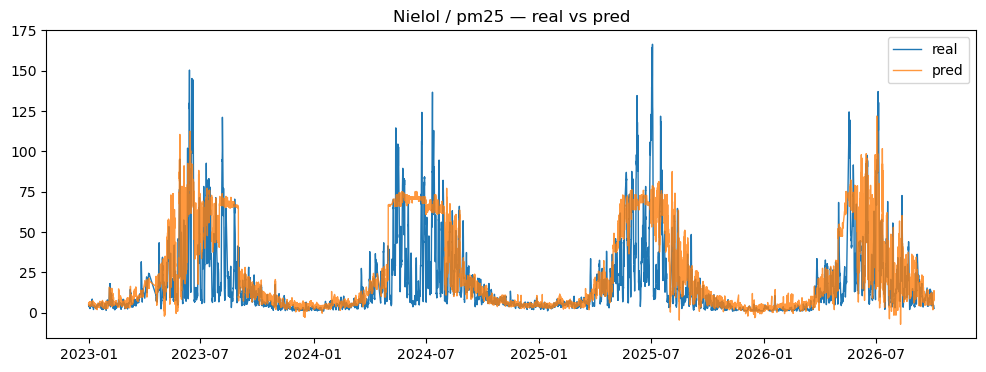

In [5]:
# Plot rápido de ejemplo: serie real vs pred (si hay predicciones).
if pred is not None and not pred.empty:
    one = pred.iloc[0]
    serie = pred[(pred.estacion == one.estacion) & (pred.pollutant == one.pollutant)].sort_values("timestamp")
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(serie.timestamp, serie.y_true, label="real", lw=1)
    ax.plot(serie.timestamp, serie.y_pred, label="pred", lw=1, alpha=0.8)
    ax.set_title(f"{one.estacion} / {one.pollutant} — real vs pred")
    ax.legend()
    plt.show()

## Al terminar

1. Guardá este notebook (Ctrl+S). Queda en el **EBS de 5 GB** del Space: persiste aunque apagues.
2. **Apagá el Space**: SageMaker Console → Studio → Spaces → `sinca-dev` → **Stop**.

> Con la app detenida, `aws sagemaker list-apps` queda vacío y **deja de facturar cómputo** (~USD 0.05–0.08/h del `ml.t3.large` mientras estuviera encendida). El EBS sigue cobrando centavos (~USD 0.40/mes).